In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from config import PROCESSED_DATA_DIR, IMAGES_DIR

sns.set_style("whitegrid")
df = pd.read_csv(PROCESSED_DATA_DIR / "clean_online_retail.csv", parse_dates=['invoice_date'])
snapshot_date = df['invoice_date'].max() + pd.Timedelta(days=1)

# Re-build RFM
rfm = df.groupby('customer_id').agg({
    'invoice_date': lambda x: (snapshot_date - x.max()).days,
    'invoice': 'nunique',
    'total_spend': 'sum'
}).reset_index()
rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']
rfm['churned'] = (rfm['recency'] > 90).astype(int)

In [2]:
X = rfm[['frequency', 'monetary']]
y = rfm['churned']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# Get probabilities (how likely is this customer to churn?)
rfm_test = rfm.loc[X_test.index].copy()
rfm_test['churn_prob'] = rf_model.predict_proba(X_test)[:, 1]

In [3]:
# Let's say the business sends a £10 discount code to customers flagged as high risk
# Historical campaign data shows this saves 15% of the churners who receive it.

DISCOUNT_COST = 10
RETENTION_RATE = 0.15

# How many customers in the test set are actually churning?
actual_churners = rfm_test['churned'].sum()
print(f"Total actual churners in test set: {actual_churners}")

# If we target customers with a churn probability > 0.50
targeted_customers = rfm_test[rfm_test['churn_prob'] > 0.50]
print(f"Customers targeted by model (probability > 50%): {len(targeted_customers)}")

# Of those targeted, how many were ACTUALLY going to churn? (We catch these!)
true_positives = targeted_customers['churned'].sum()
print(f"Actual churners caught in targeted group: {true_positives}")

# How much revenue do we save?
saved_customers = true_positives * RETENTION_RATE
avg_customer_value = rfm['monetary'].mean()
revenue_saved = saved_customers * avg_customer_value
campaign_cost = len(targeted_customers) * DISCOUNT_COST
net_profit = revenue_saved - campaign_cost

print(f"\n--- Campaign Financials ---")
print(f"Revenue Saved:     £{revenue_saved:,.2f}")
print(f"Campaign Cost:     £{campaign_cost:,.2f}")
print(f"Net Profit:        £{net_profit:,.2f}")

Total actual churners in test set: 290
Customers targeted by model (probability > 50%): 460
Actual churners caught in targeted group: 236

--- Campaign Financials ---
Revenue Saved:     £72,721.18
Campaign Cost:     £4,600.00
Net Profit:        £68,121.18


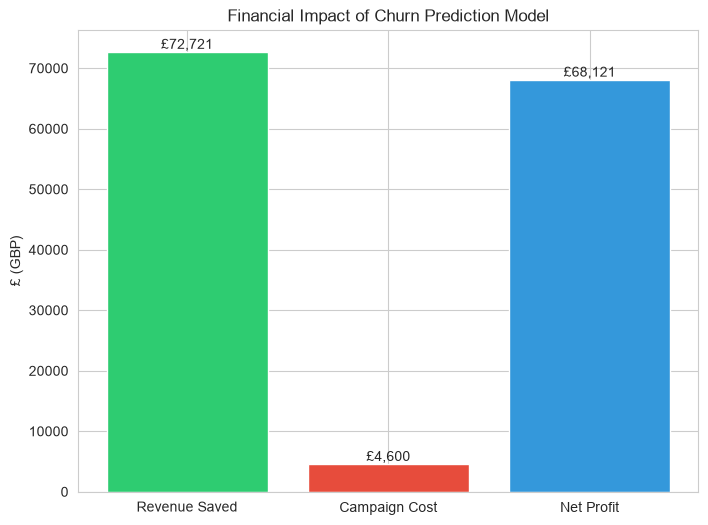

In [4]:
# Bar chart of financial impact
plt.figure(figsize=(8, 6))
bars = plt.bar(['Revenue Saved', 'Campaign Cost', 'Net Profit'], 
               [revenue_saved, campaign_cost, net_profit],
               color=['#2ecc71', '#e74c3c', '#3498db'])
plt.title('Financial Impact of Churn Prediction Model')
plt.ylabel('£ (GBP)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'£{yval:,.0f}', ha='center', va='bottom')
plt.savefig(IMAGES_DIR / "campaign_roi.png", dpi=150)
plt.show()